# Initial environment setup and validation

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
PATH = r"C:\Users\Benjamin Lindblom\BTCRSGPM\data\preprocessed.npy"
dataset = np.load(PATH, allow_pickle=True) # Dataset from the APOLLO (2023) paper, preprocessed and saved as a NumPy array.

In [19]:
print("Shape:", dataset.shape)
print("Data type:", dataset.dtype)
print("Dimensions:", dataset.ndim)
print("Number of elements:", dataset.size)
print("Memory:", dataset.nbytes, "bytes")
print(dataset)

Shape: (59,)
Data type: object
Dimensions: 1
Number of elements: 59
Memory: 472 bytes
[{'data': array([[[1.12586081e-02, 0.00000000e+00, 0.00000000e+00, ...,
          1.44051225e-03, 9.64099361e-05, 4.96001031e-04],
         [2.41162764e-03, 4.89834832e-03, 6.00873493e-03, ...,
          0.00000000e+00, 1.45184602e-02, 1.17679116e-02],
         [2.72575047e-03, 0.00000000e+00, 2.16562918e-04, ...,
          1.36039162e-02, 4.84496678e-03, 3.44093923e-03],
         ...,
         [1.13009690e-03, 3.13478542e-03, 4.34356679e-03, ...,
          2.00119337e-03, 7.99264127e-03, 5.13989776e-03],
         [2.84740690e-03, 4.11731089e-03, 5.85303577e-03, ...,
          7.19129439e-03, 5.54758333e-03, 2.69111022e-03],
         [2.66281933e-03, 3.54517019e-03, 1.92315271e-03, ...,
          1.40930957e-03, 2.87646852e-03, 5.78533615e-03]],

        [[8.60352731e-04, 5.80759080e-03, 7.16498301e-03, ...,
          9.27399393e-03, 3.81102463e-03, 2.04417152e-03],
         [1.09308270e-03, 3.8625030

In [27]:
item = dataset[0]

for key, value in item.items():
    if isinstance(value, np.ndarray):
        print(f"{key}: shape={value.shape}, dtype={value.dtype}")
    else:
        print(f"{key}: type={type(value).__name__}, value={value}")

data: shape=(121, 51, 1167), dtype=float64
name: type=str, value=HF-305_v4b_1_1.h5_6
class_id: type=int, value=2
patient_id: type=int, value=305
tsne: shape=(6171, 2), dtype=float32
pca: shape=(6171, 2), dtype=float64


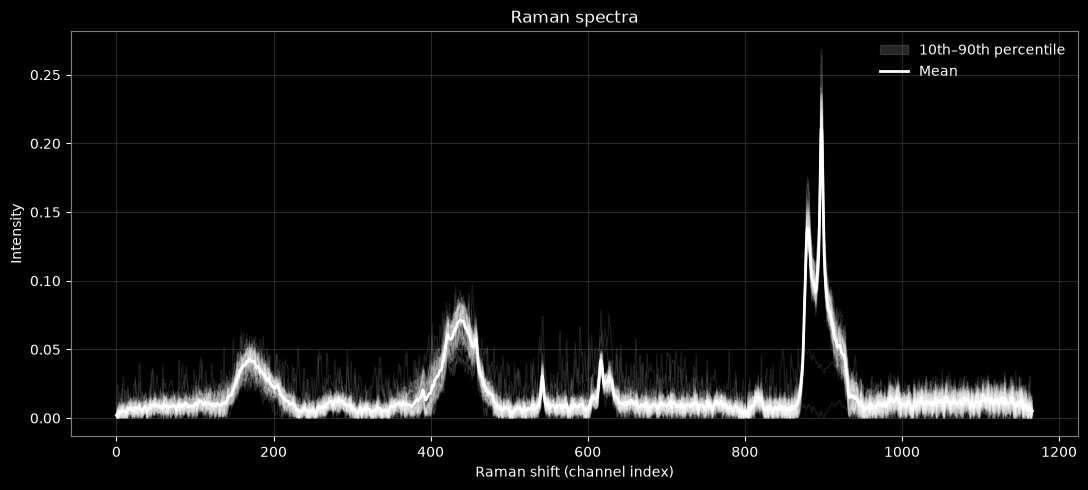

In [ ]:
spectra = dataset[0]["data"][0]
x = np.arange(spectra.shape[1])
mean = spectra.mean(axis=0)
low, high = np.percentile(spectra, [10, 90], axis=0)

fig, ax = plt.subplots(figsize=(11, 5), facecolor="black")
ax.set_facecolor("black")

ax.plot(x, spectra.T, color="white", alpha=0.12, lw=0.8)
ax.fill_between(x, low, high, color="gray", alpha=0.3, label="10th–90th percentile")
ax.plot(x, mean, color="white", lw=2, label="Mean")

ax.set(title="Raman spectra", xlabel="Raman shift (channel index)", ylabel="Intensity")
ax.tick_params(colors="white")
ax.title.set_color("white")
ax.xaxis.label.set_color("white")
ax.yaxis.label.set_color("white")
ax.grid(color="gray", alpha=0.3)
for spine in ax.spines.values():
    spine.set_color("gray")

ax.legend(frameon=False, labelcolor="white")
plt.tight_layout()
plt.show()

In [46]:
for i, item in enumerate(dataset[:3]):
    print(f"Entry {i}:")
    for key, value in item.items():
        if isinstance(value, np.ndarray):
            print(f"  {key}: array, shape={value.shape}, dtype={value.dtype}")
        else:
            print(f"  {key}: {value!r}")

Entry 0:
  data: array, shape=(121, 51, 1167), dtype=float64
  name: 'HF-305_v4b_1_1.h5_6'
  class_id: 2
  patient_id: 305
  tsne: array, shape=(6171, 2), dtype=float32
  pca: array, shape=(6171, 2), dtype=float64
Entry 1:
  data: array, shape=(50, 50, 1167), dtype=float64
  name: 'HF-442_V4BB_1.h5_12'
  class_id: 4
  patient_id: 442
  tsne: array, shape=(2500, 2), dtype=float32
  pca: array, shape=(2500, 2), dtype=float64
Entry 2:
  data: array, shape=(60, 60, 1167), dtype=float64
  name: 'HF-448_V5B_1.h5_3'
  class_id: 1
  patient_id: 448
  tsne: array, shape=(3600, 2), dtype=float32
  pca: array, shape=(3600, 2), dtype=float64


In [47]:
from collections import Counter

counts = Counter(item["patient_id"] for item in dataset)
print(counts)

Counter({2849: 4, 2102: 3, 2104: 3, 682: 2, 894: 2, 988: 2, 1002: 2, 2493: 2, 2619: 2, 305: 1, 442: 1, 448: 1, 592: 1, 615: 1, 868: 1, 901: 1, 960: 1, 1010: 1, 1016: 1, 1043: 1, 1086: 1, 1293: 1, 1295: 1, 1334: 1, 1825: 1, 1887: 1, 2070: 1, 2106: 1, 2355: 1, 2454: 1, 2485: 1, 2534: 1, 2544: 1, 2548: 1, 2600: 1, 2608: 1, 2614: 1, 2666: 1, 2715: 1, 2776: 1, 2802: 1, 2852: 1, 2876: 1, 2898: 1, 3271: 1, 3337: 1})


In [48]:
from collections import defaultdict

classes = defaultdict(set)
for item in dataset:
    classes[item["patient_id"]].add(item["class_id"])

inconsistent = {p: c for p, c in classes.items() if len(c) > 1}
print("Patients with multiple class IDs:", inconsistent)

Patients with multiple class IDs: {}
